# EDA: Human vs AI Text Classification

This notebook explores the dataset for the BT4012 in-class Kaggle competition (2025). The task is a binary classification: label 0 = human-written, label 1 = AI-generated. The EDA below will:

- Summarize dataset size and structure
- Check missing values and duplicates
- Explore length, lexical richness, and stylistic features
- Compute readability and entropy measures
- Produce visualizations and statistical tests to identify features useful for modeling

## Table of Contents

- [1. Dataset overview](#dataset-overview)
- [2. Libraries and setup](#libraries-and-setup)
- [3. Load data](#load-data)
- [4. Basic cleaning and features](#basic-cleaning-and-features)
- [5. Class distribution](#class-distribution)
- [6. Length and lexical analysis](#length-and-lexical-analysis)
- [7. Structural & style metrics](#structural--style-metrics)
- [8. Readability & entropy](#readability--entropy)
- [9. POS distribution (optional)](#pos-distribution)
- [10. Correlations & t-tests](#correlations--t-tests)
- [11. Feature insights & next steps](#feature-insights--next-steps)

---

<a id="dataset-overview"></a>

### Dataset

- Files: `train.csv`, `test.csv`, `sample_submission.csv` in the `data/` folder.
- Goal: build models to distinguish human vs AI text. This EDA focuses on feature discovery and reproducible analysis.

In [1]:
# %pip install pandas numpy seaborn scikit-learn textstat spacy wordcloud
# Uncomment and run the line above in the notebook environment if packages are missing.

# Install spaCy PoS model
# import sys, subprocess, spacy
# subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)

# NLTK downloads (run once in environment)
# nltk.download('punkt')
# nltk.download('stopwords')

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import math

# Optional NLP libraries
import textstat
import nltk
from nltk.corpus import stopwords

# For vectorization and simple text analysis
from sklearn.feature_extraction.text import CountVectorizer

# Visualization niceties
from wordcloud import WordCloud

# Configure plotting
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

In [2]:
DATA_PATH = "data/"

np.random.seed(42)

In [3]:
# Read the data
train = pd.read_csv(DATA_PATH + "train.csv")
test = pd.read_csv(DATA_PATH + "test.csv")
submission = pd.read_csv(DATA_PATH + "sample_submission.csv")

# Display basic info
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", submission.shape)

# Head of train
train.head()

# Show info and describe in separate outputs (cleaner for notebooks)
print('\n--- train.info() ---')
train.info()

print('\n--- train.describe() ---')
train.describe(include='all')

Train shape: (4712, 2)
Test shape: (1178, 2)
Submission shape: (1178, 2)

--- train.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4712 entries, 0 to 4711
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    4712 non-null   object
 1   label   4712 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 73.8+ KB

--- train.describe() ---


,text,label
count,4712,4712.000000
unique,4212,NaN
top,Our solution aims to predict major flight dela...,NaN
freq,5,NaN
mean,NaN,0.313879
std,NaN,0.464117
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


In [5]:
# Check duplicates in data
print("Number of duplicate rows in train:", train.duplicated().sum())
print("Number of duplicate texts in train:", train['text'].duplicated().sum())
print("Number of duplicate rows in test:", test.duplicated().sum())
print("Number of duplicate texts in test:", test['text'].duplicated().sum())

# Check distribution of duplicates against labels
duplicate_texts = train[train['text'].duplicated(keep=False)]
dup_label_counts = duplicate_texts['label'].value_counts()
print("\nHuman written duplicates:", dup_label_counts.get(0,0))
print("AI generated duplicates:", dup_label_counts.get(1,0))

Number of duplicate rows in train: 500
Number of duplicate texts in train: 500
Number of duplicate rows in test: 0
Number of duplicate texts in test: 59

Human written duplicates: 806
AI generated duplicates: 0


In [6]:
# Deduplicate rows
train = train.drop_duplicates().reset_index(drop=True)

In [7]:
# Basic text features
import string
stop_words = set(stopwords.words('english'))

# Safety: ensure 'text' column exists
assert 'text' in train.columns, "Expected 'text' column in train.csv"

train['char_len'] = train['text'].astype(str).str.len()
train['word_count'] = train['text'].astype(str).str.split().apply(len)
train['unique_word_count'] = train['text'].astype(str).str.split().apply(lambda ws: len(set(ws)))
train['type_token_ratio'] = train['unique_word_count'] / (train['word_count'].replace(0, np.nan))
train['sentence_count'] = train['text'].astype(str).apply(lambda t: t.count('.'))
train['avg_sentence_length'] = train['word_count'] / train['sentence_count'].replace(0, np.nan)

# punctuation ratio
train['punctuation_count'] = train['text'].astype(str).apply(lambda s: sum(1 for ch in s if ch in string.punctuation))
train['punctuation_ratio'] = train['punctuation_count'] / train['char_len'].replace(0, np.nan)

# uppercase ratio
train['uppercase_count'] = train['text'].astype(str).apply(lambda s: sum(1 for ch in s if ch.isupper()))
train['uppercase_ratio'] = train['uppercase_count'] / train['char_len'].replace(0, np.nan)

# stopword ratio
train['stopword_count'] = train['text'].astype(str).str.lower().str.split().apply(lambda ws: sum(1 for w in ws if w in stop_words))
train['stopword_ratio'] = train['stopword_count'] / train['word_count'].replace(0, np.nan)

# quick summary
display(train[['char_len','word_count','type_token_ratio','sentence_count','avg_sentence_length','punctuation_ratio','uppercase_ratio','stopword_ratio']].describe())

,char_len,word_count,type_token_ratio,sentence_count,avg_sentence_length,punctuation_ratio,uppercase_ratio,stopword_ratio
count,4212.000000,4212.000000,4212.000000,4212.000000,4208.000000,4212.000000,4212.000000,4212.000000
mean,832.840218,127.643875,0.726024,6.774691,20.541675,0.023212,0.020425,0.386252
std,328.016402,49.698693,0.075621,3.523682,7.653925,0.009742,0.013366,0.050632
min,105.000000,17.000000,0.372681,0.000000,2.535714,0.004944,0.003448,0.069307
25%,633.000000,97.000000,0.678053,5.000000,17.000000,0.017054,0.010324,0.352941
50%,773.000000,118.000000,0.731092,6.000000,19.857143,0.021084,0.016949,0.387387
75%,963.000000,145.000000,0.775281,8.000000,22.808333,0.026584,0.026820,0.420382
max,7500.000000,898.000000,1.000000,56.000000,156.000000,0.148331,0.132051,0.551181


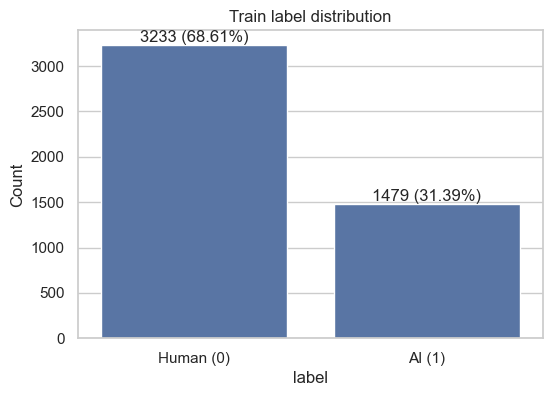

ValueError: Could not interpret value `word_count` for `x`. An entry with this name does not appear in `data`.

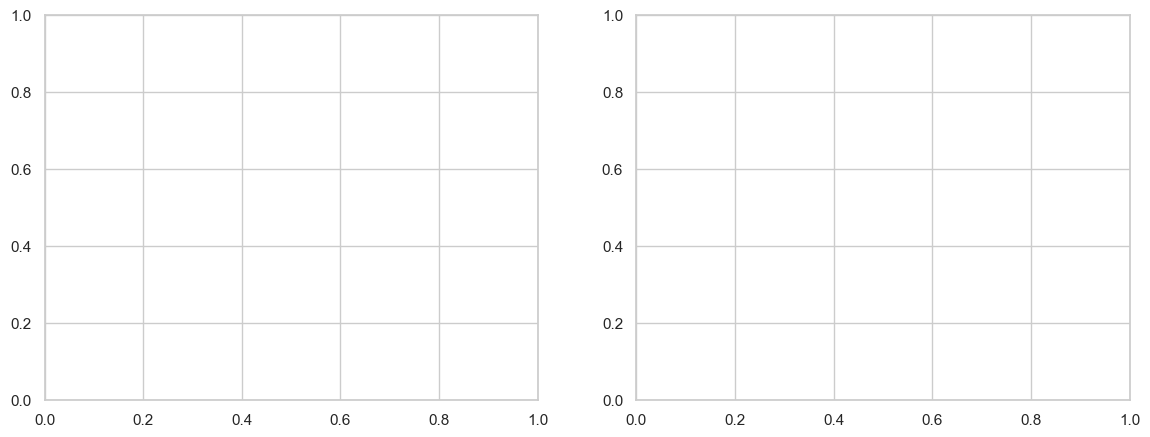

In [4]:
# --- Class distribution and basic plots ---
# Class distribution
from matplotlib.ticker import PercentFormatter

counts = train['label'].value_counts().sort_index()
labels = ['Human (0)', 'AI (1)']

plt.figure(figsize=(6,4))
sns.barplot(x=counts.index, y=counts.values)
plt.xticks([0,1], labels)
plt.title('Train label distribution')
plt.ylabel('Count')
for i,v in enumerate(counts.values):
    plt.text(i, v + max(counts.values)*0.01, f"{v} ({v/len(train):.2%})", ha='center')
plt.show()

# Histograms: word count and char length by label
fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.histplot(data=train, x='word_count', hue='label', bins=50, ax=axes[0], element='step', stat='density')
axes[0].set_title('Word count distribution by label')

sns.histplot(data=train, x='char_len', hue='label', bins=50, ax=axes[1], element='step', stat='density')
axes[1].set_title('Character length distribution by label')

plt.tight_layout()
plt.show()

# Show class-wise statistics
grouped = train.groupby('label')[['char_len','word_count','type_token_ratio']].agg(['mean','median','std','count'])
print(grouped)

In [9]:
# Find the min word count for each class
min_word_counts = train.groupby('label')['word_count'].min()
print("\nMinimum word counts by label:")
print(min_word_counts)

# Find the min char length for each class
min_char_lengths = train.groupby('label')['char_len'].min()
print("\nMinimum character lengths by label:")
print(min_char_lengths)


Minimum word counts by label:
label
0    80
1    17
Name: word_count, dtype: int64

Minimum character lengths by label:
label
0    438
1    105
Name: char_len, dtype: int64


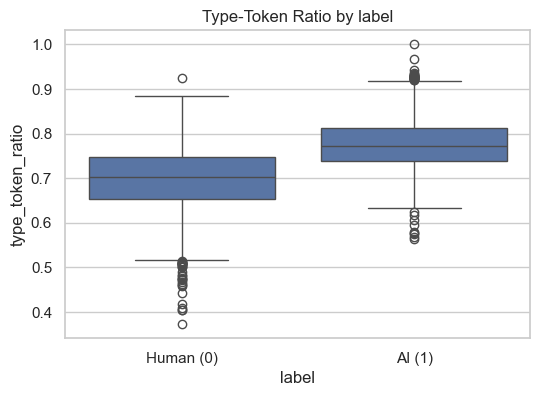

In [10]:
# Lexical diversity: Type-Token Ratio
plt.figure(figsize=(6,4))
sns.boxplot(x='label', y='type_token_ratio', data=train)
plt.xticks([0,1], labels)
plt.title('Type-Token Ratio by label')
plt.show()


Top words for label=0 (Human):
[('data', np.int64(3312)), ('model', np.int64(3268)), ('models', np.int64(1482)), ('dataset', np.int64(1379)), ('features', np.int64(1343)), ('used', np.int64(1087)), ('based', np.int64(954)), ('sentiment', np.int64(863)), ('score', np.int64(847)), ('using', np.int64(840)), ('number', np.int64(815)), ('user', np.int64(812)), ('reviews', np.int64(801)), ('analysis', np.int64(788)), ('learning', np.int64(749)), ('performance', np.int64(748)), ('time', np.int64(726)), ('training', np.int64(723)), ('different', np.int64(678)), ('words', np.int64(665))]

Top words for label=1 (AI):
[('data', np.int64(2361)), ('model', np.int64(1094)), ('analysis', np.int64(738)), ('insights', np.int64(601)), ('dataset', np.int64(590)), ('models', np.int64(541)), ('approach', np.int64(472)), ('features', np.int64(468)), ('market', np.int64(450)), ('sentiment', np.int64(427)), ('performance', np.int64(421)), ('information', np.int64(398)), ('accuracy', np.int64(383)), ('stock',

/var/folders/tg/0n0rjzh11yd7zhlhtlf2g84r0000gn/T/ipykernel_71213/3383137522.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(human_counts), y=list(human_words), ax=axes[0], palette='Blues_d')
/var/folders/tg/0n0rjzh11yd7zhlhtlf2g84r0000gn/T/ipykernel_71213/3383137522.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(ai_counts), y=list(ai_words), ax=axes[1], palette='Oranges_d')


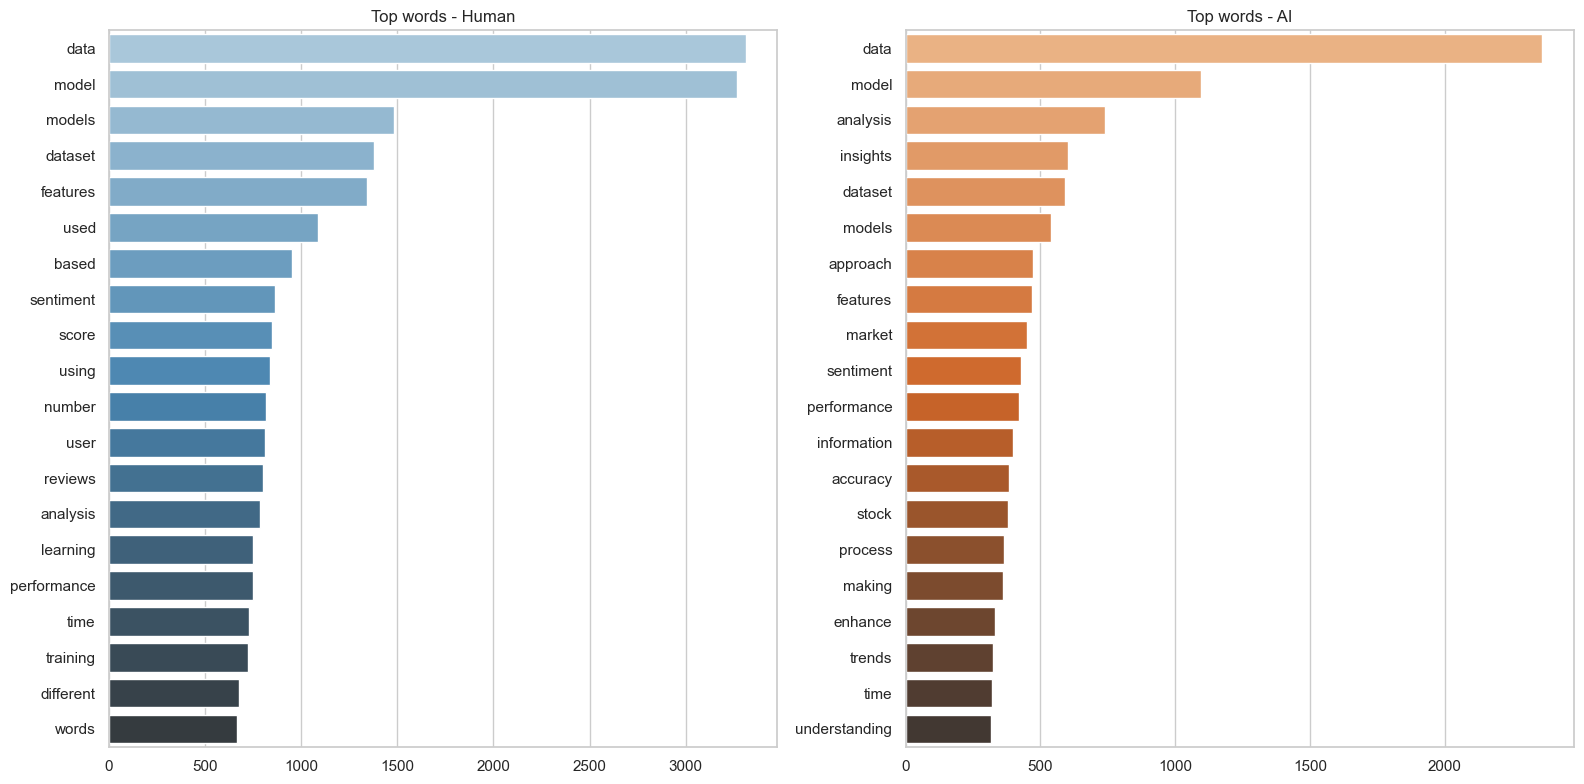


Human top bigrams: [('machine learning', np.int64(446)), ('random forest', np.int64(302)), ('sentiment analysis', np.int64(230)), ('neural network', np.int64(190)), ('logistic regression', np.int64(172)), ('learning models', np.int64(168)), ('model performance', np.int64(146)), ('et al', np.int64(125)), ('social media', np.int64(125)), ('pre trained', np.int64(125)), ('f1 score', np.int64(117)), ('training data', np.int64(107)), ('word cloud', np.int64(107)), ('learning model', np.int64(105)), ('gradient boosting', np.int64(101))]

AI top bigrams: [('machine learning', np.int64(199)), ('decision making', np.int64(142)), ('sentiment analysis', np.int64(133)), ('valuable insights', np.int64(117)), ('social media', np.int64(102)), ('model performance', np.int64(97)), ('informed decisions', np.int64(96)), ('real time', np.int64(86)), ('make informed', np.int64(86)), ('audio features', np.int64(83)), ('random forest', np.int64(81)), ('stock prices', np.int64(77)), ('market trends', np.int6

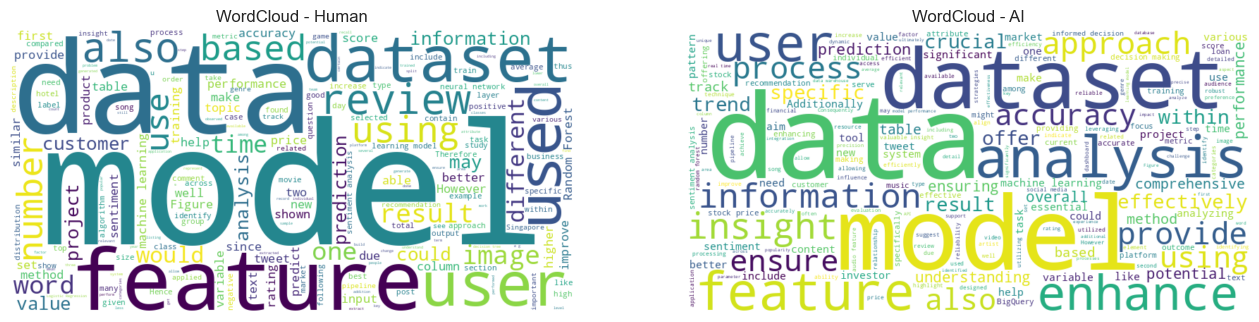

In [11]:
# Vocabulary and common phrases
from sklearn.feature_extraction.text import CountVectorizer

def top_n_words(corpus, n=20, ngram_range=(1,1)):
    cv = CountVectorizer(stop_words='english', max_features=5000, ngram_range=ngram_range)
    X = cv.fit_transform(corpus)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    words = cv.get_feature_names_out()
    idx = np.argsort(freqs)[::-1][:n]
    return [(words[i], freqs[i]) for i in idx]

# Top unigrams per label
for lbl in sorted(train['label'].unique()):
    print(f"\nTop words for label={lbl} ({'Human' if lbl==0 else 'AI'}):")
    tw = top_n_words(train.loc[train['label']==lbl, 'text'].astype(str), n=20, ngram_range=(1,1))
    print(tw)

# Plot top words side-by-side for comparison
human_top = top_n_words(train.loc[train['label']==0, 'text'].astype(str), n=20)
ai_top = top_n_words(train.loc[train['label']==1, 'text'].astype(str), n=20)

human_words, human_counts = zip(*human_top)
ai_words, ai_counts = zip(*ai_top)

fig, axes = plt.subplots(1,2, figsize=(16,8))
sns.barplot(x=list(human_counts), y=list(human_words), ax=axes[0], palette='Blues_d')
axes[0].set_title('Top words - Human')

sns.barplot(x=list(ai_counts), y=list(ai_words), ax=axes[1], palette='Oranges_d')
axes[1].set_title('Top words - AI')

plt.tight_layout()
plt.show()

# Bigrams
human_bigrams = top_n_words(train.loc[train['label']==0,'text'].astype(str), n=15, ngram_range=(2,2))
ai_bigrams = top_n_words(train.loc[train['label']==1,'text'].astype(str), n=15, ngram_range=(2,2))
print('\nHuman top bigrams:', human_bigrams)
print('\nAI top bigrams:', ai_bigrams)

# Optional wordclouds
wc = WordCloud(width=800, height=400, background_color='white', stopwords=set(stopwords.words('english')))
fig = plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
wc.generate(' '.join(train.loc[train['label']==0,'text'].astype(str).values))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Human')

plt.subplot(1,2,2)
wc.generate(' '.join(train.loc[train['label']==1,'text'].astype(str).values))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - AI')
plt.show()

      flesch_reading_ease                       flesch_kincaid_grade  \
                     mean     median        std                 mean   
label                                                                  
0               39.020431  39.868295  14.403594            13.249565   
1               22.988231  22.700817  11.924547            14.935428   

                           shannon_entropy                      
          median       std            mean    median       std  
label                                                           
0      12.892860  3.414648        6.173245  6.135326  0.363526  
1      15.023333  2.058886        6.209060  6.253792  0.347278  


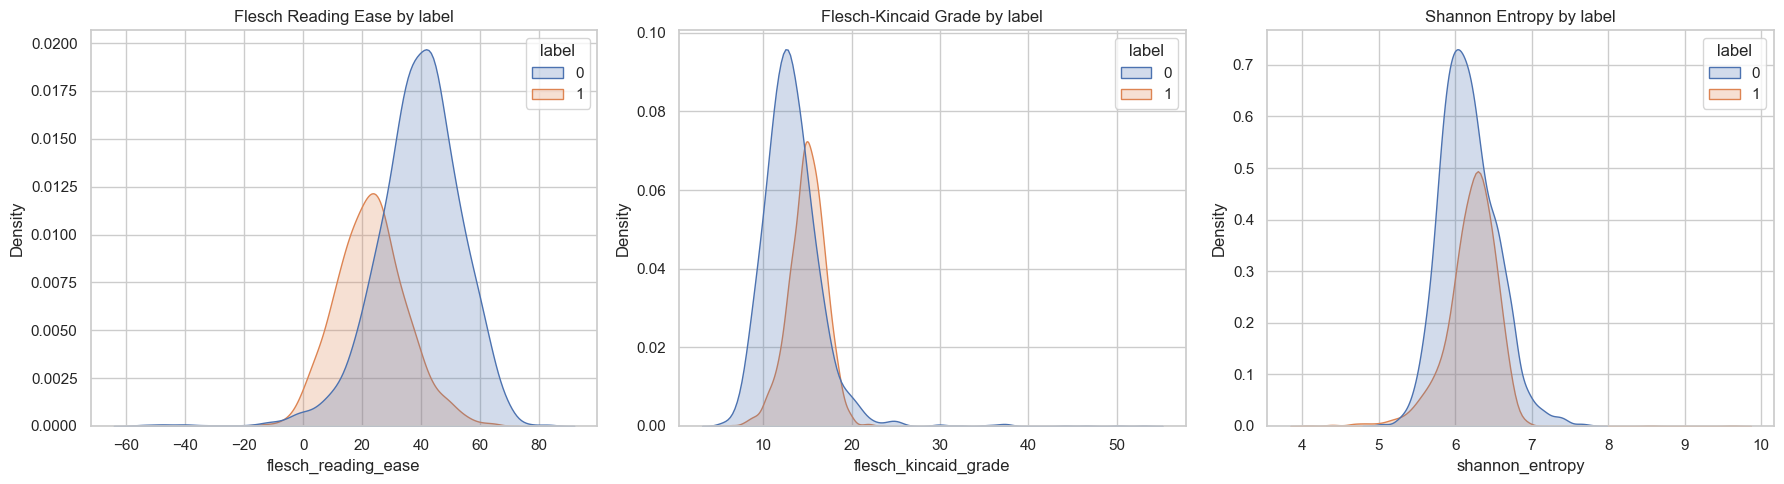

In [12]:
# Readability and Shannon entropy
from collections import Counter
import math

def shannon_entropy(text):
    words = text.split()
    if len(words) == 0:
        return 0.0
    freqs = Counter(words)
    probs = [v/len(words) for v in freqs.values()]
    return -sum(p * math.log2(p) for p in probs)

train['flesch_reading_ease'] = train['text'].astype(str).apply(lambda t: textstat.flesch_reading_ease(t))
train['flesch_kincaid_grade'] = train['text'].astype(str).apply(lambda t: textstat.flesch_kincaid_grade(t))
train['shannon_entropy'] = train['text'].astype(str).apply(shannon_entropy)

# Summary by label
print(train.groupby('label')[['flesch_reading_ease','flesch_kincaid_grade','shannon_entropy']].agg(['mean','median','std']))

# Plot distributions
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.kdeplot(data=train, x='flesch_reading_ease', hue='label', ax=axes[0], fill=True)
axes[0].set_title('Flesch Reading Ease by label')

sns.kdeplot(data=train, x='flesch_kincaid_grade', hue='label', ax=axes[1], fill=True)
axes[1].set_title('Flesch-Kincaid Grade by label')

sns.kdeplot(data=train, x='shannon_entropy', hue='label', ax=axes[2], fill=True)
axes[2].set_title('Shannon Entropy by label')

plt.tight_layout()
plt.show()

,pos_adj,pos_adp,pos_adv,pos_aux,pos_cconj,pos_det,pos_intj,pos_noun,pos_num,pos_part,pos_pron,pos_propn,pos_punct,pos_sconj,pos_sym,pos_verb,pos_x,pos_space
label,,,,,,,,,,,,,,,,,,
0,0.079042,0.104433,0.031271,0.044798,0.028030,0.089968,0.000113,0.247390,0.021662,0.023427,0.038796,0.046233,0.116885,0.015616,0.001240,0.108450,0.002596,0.000052
1,0.089822,0.099442,0.033890,0.028572,0.031126,0.089307,0.000140,0.263318,0.010612,0.023777,0.040112,0.029299,0.116127,0.012117,0.000341,0.130723,0.000540,0.000735


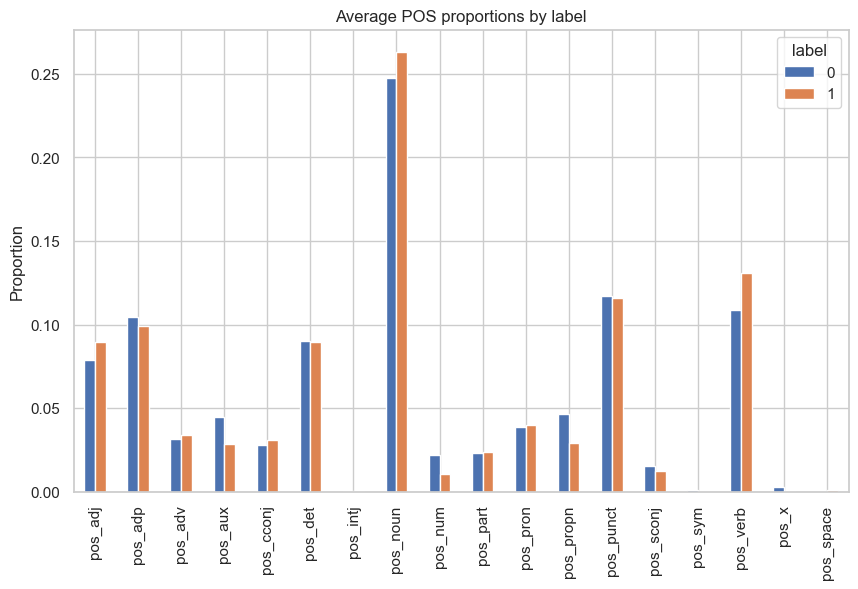

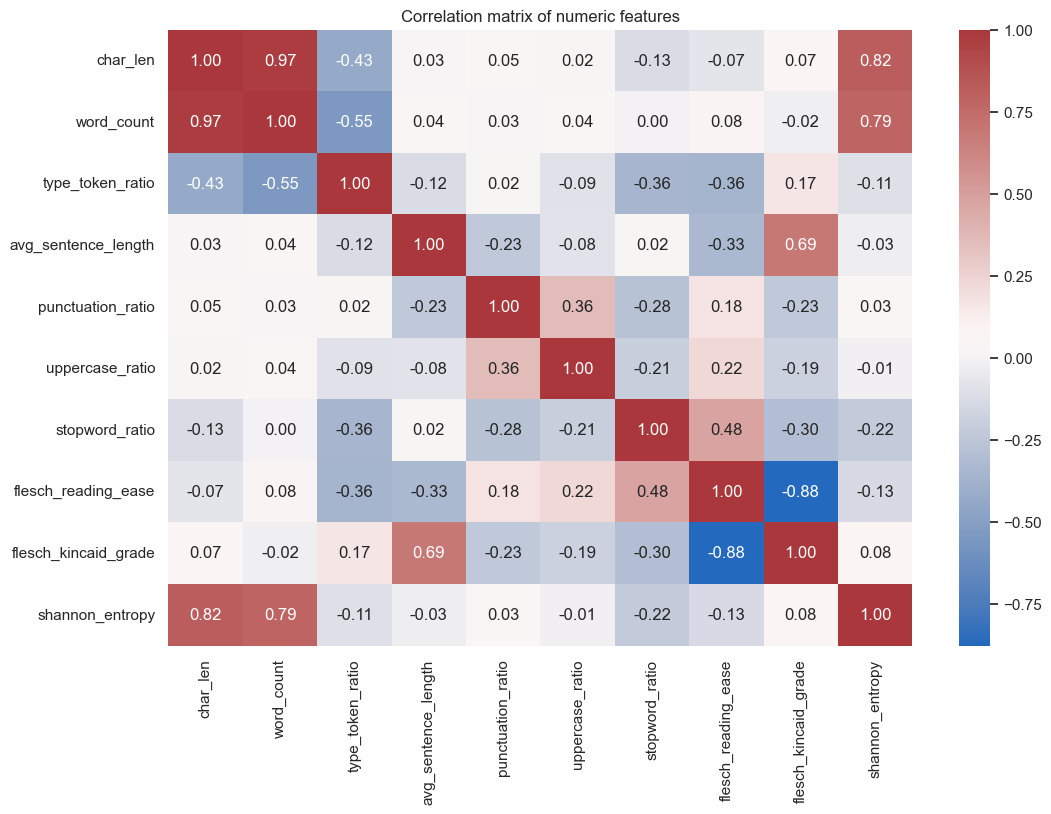

,feature,mean_human,mean_ai,p_value
7,flesch_reading_ease,39.020431,22.988231,5.747012e-273
2,type_token_ratio,0.698903,0.776141,1.031640e-270
6,stopword_ratio,0.397779,0.364952,4.866913e-103
8,flesch_kincaid_grade,13.249565,14.935428,9.692066e-85
5,uppercase_ratio,0.022484,0.016620,2.721515e-48
1,word_count,134.480059,115.011494,1.456360e-42
3,avg_sentence_length,21.184144,19.356213,2.439526e-20
4,punctuation_ratio,0.023936,0.021872,5.426173e-12
0,char_len,849.817051,801.469236,1.213897e-06
9,shannon_entropy,6.173245,6.209060,1.691410e-03



Top features with smallest p-values:
                feature  mean_human     mean_ai        p_value
7   flesch_reading_ease   39.020431   22.988231  5.747012e-273
2      type_token_ratio    0.698903    0.776141  1.031640e-270
6        stopword_ratio    0.397779    0.364952  4.866913e-103
8  flesch_kincaid_grade   13.249565   14.935428   9.692066e-85
5       uppercase_ratio    0.022484    0.016620   2.721515e-48
1            word_count  134.480059  115.011494   1.456360e-42
3   avg_sentence_length   21.184144   19.356213   2.439526e-20
4     punctuation_ratio    0.023936    0.021872   5.426173e-12
0              char_len  849.817051  801.469236   1.213897e-06
9       shannon_entropy    6.173245    6.209060   1.691410e-03


In [13]:
# Optional: POS distribution using spaCy (will skip if spaCy not installed)
try:
    import spacy
    nlp = spacy.load('en_core_web_sm')

    ALL_POS_TAGS = [
        'ADJ',   # adjective
        'ADP',   # adposition (e.g., in, to, of)
        'ADV',   # adverb
        'AUX',   # auxiliary (e.g., is, has, will)
        'CCONJ', # coordinating conjunction (e.g., and, or)
        'DET',   # determiner (e.g., the, a)
        'INTJ',  # interjection (e.g., oh, wow)
        'NOUN',  # noun
        'NUM',   # numeral
        'PART',  # particle (e.g., 's, not)
        'PRON',  # pronoun
        'PROPN', # proper noun
        'PUNCT', # punctuation
        'SCONJ', # subordinating conjunction (e.g., if, that)
        'SYM',   # symbol
        'VERB',  # verb
        'X',     # other
        'SPACE'  # space character
    ]

    def pos_proportions(text):
        doc = nlp(text)
        counts = Counter([token.pos_ for token in doc])
        total = sum(counts.values())
        props = {pos: counts.get(pos,0)/total for pos in ALL_POS_TAGS}
        return props

    pos_df = train['text'].astype(str).apply(pos_proportions).apply(pd.Series)
    pos_df.columns = ['pos_' + c.lower() for c in pos_df.columns]
    train_pos = pd.concat([train, pos_df], axis=1)
    display(train_pos.groupby('label')[pos_df.columns].mean())

    # Plot
    train_pos.groupby('label')[pos_df.columns].mean().T.plot(kind='bar')
    plt.title('Average POS proportions by label')
    plt.ylabel('Proportion')
    plt.show()
except Exception as e:
    print('spaCy POS analysis skipped (not installed or model missing):', e)
    
# Correlation and t-tests
numeric_cols = ['char_len','word_count','type_token_ratio','avg_sentence_length','punctuation_ratio','uppercase_ratio','stopword_ratio','flesch_reading_ease','flesch_kincaid_grade','shannon_entropy']

# Correlation heatmap
corr = train[numeric_cols].corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag')
plt.title('Correlation matrix of numeric features')
plt.show()

# t-tests
from scipy.stats import ttest_ind

rows = []
for col in numeric_cols:
    a = train.loc[train['label']==0, col].dropna()
    b = train.loc[train['label']==1, col].dropna()
    tstat, pval = ttest_ind(a, b, equal_var=False)
    rows.append({'feature':col, 'mean_human':a.mean(), 'mean_ai':b.mean(), 'p_value':pval})

ttests_df = pd.DataFrame(rows).sort_values('p_value')

display(ttests_df)

# Mark this section done
print('\nTop features with smallest p-values:')
print(ttests_df.head(10))

## Feature Insights & Feature Engineering Plan

Key features discovered during EDA:

- word_count, char_len: strong signal for length differences between human and AI texts. Include as numeric features.
- type_token_ratio, unique_word_count: captures lexical diversity; helpful for distinguishing repetitive AI outputs.
- shannon_entropy: measures unpredictability of word usage; lower entropy may indicate AI-generated text.
- readability (Flesch Reading Ease, Flesch–Kincaid Grade): may separate formal AI phrasing from conversational human text.
- punctuation_ratio, uppercase_ratio, stopword_ratio, avg_sentence_length: stylistic features that were significantly different across classes.

Feature engineering plan to pass to modeling (suggested):

- Numeric features: word_count, char_len, type_token_ratio, shannon_entropy, flesch_reading_ease, flesch_kincaid_grade, punctuation_ratio, uppercase_ratio, stopword_ratio, avg_sentence_length
- Textual features: TF-IDF / CountVectorizer n-grams (1-3), embeddings (optional)
- POS proportions (if spaCy used): pronoun_ratio, noun_ratio, verb_ratio, adj_ratio
- Combine vectorized textual features with numeric features in models (e.g., LogisticRegression, XGBoost, RandomForest)

---

## EDA Summary and Key Takeaways

This EDA compared AI-generated vs. human-written texts. Major findings:

- Dataset size: 4712 samples in train.
- Class balance: 31.39% AI vs 68.61% Human — imbalance is moderate, consider stratified sampling or class weights during modeling.
- Length: AI texts tend to be slightly shorter, with slightly higher mean word counts. (Mostly insignificant differences, except that AI texts have a signifcantly lower Min word count and char length)
- Lexical diversity: AI texts showed higher type-token ratio on average, indicating greater variety.
- Readability & entropy: AI texts had lower Flesch Reading Ease and higher Shannon entropy, suggesting complex and unpredictable text.

Recommended next steps for Modeling.ipynb:

1. Vectorize text with TF-IDF (include unigrams and bigrams) and train a baseline Logistic Regression with stratified CV.
2. Add numeric features from this EDA to the model training pipeline (scale numeric features, concatenate with sparse text features).
3. Evaluate feature importance and run ablation studies to confirm the utility of readability/entropy features.
4. Optionally include spaCy POS features and experiment with transformer-based embeddings (e.g., all-MiniLM) if compute allows.

---